# Задание 2

## Проверим Pandas
Скачать с Kaggle [данные с температурой по городам](https://www.kaggle.com/datasets/sudalairajkumar/daily-temperature-of-major-cities).

Если очень не хочется регистрироваться на сайте, архив *(2data.zip)* можно взять в папке с [заданием](https://disk.yandex.ru/d/MrtwhwSBdLuKKA).

In [1]:
import pandas as pd

df = pd.read_csv('02_lab_data/city_temperature.csv')
df.head()

C:\Users\ksenia\AppData\Local\Temp\ipykernel_16920\3968829038.py:3: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('02_lab_data/city_temperature.csv')


,Region,Country,State,City,Month,Day,Year,AvgTemperature
0,Africa,Algeria,NaN,Algiers,1,1,1995,64.2
1,Africa,Algeria,NaN,Algiers,1,2,1995,49.4
2,Africa,Algeria,NaN,Algiers,1,3,1995,48.8
3,Africa,Algeria,NaN,Algiers,1,4,1995,46.4
4,Africa,Algeria,NaN,Algiers,1,5,1995,47.9


Считать данные в `pandas.DataFrame`, посмотреть, что там лежит.

Если хотите вспомнить, как обращаться с DataFrame, могу порекомендовать [мини-курс](https://www.kaggle.com/code/residentmario/creating-reading-and-writing) на том же Kaggle:  там есть примеры всех нужных действий, сгруппированных на 6 страницах (считывание, обращение по индексу, изменение, типы данных).

In [2]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2906327 entries, 0 to 2906326
Data columns (total 8 columns):
 #   Column          Dtype  
---  ------          -----  
 0   Region          object 
 1   Country         object 
 2   State           object 
 3   City            object 
 4   Month           int64  
 5   Day             int64  
 6   Year            int64  
 7   AvgTemperature  float64
dtypes: float64(1), int64(3), object(4)
memory usage: 177.4+ MB


,Month,Day,Year,AvgTemperature
count,2.906327e+06,2.906327e+06,2.906327e+06,2.906327e+06
mean,6.469163e+00,1.571682e+01,2.006624e+03,5.600492e+01
std,3.456489e+00,8.800534e+00,2.338226e+01,3.212359e+01
min,1.000000e+00,0.000000e+00,2.000000e+02,-9.900000e+01
25%,3.000000e+00,8.000000e+00,2.001000e+03,4.580000e+01
50%,6.000000e+00,1.600000e+01,2.007000e+03,6.250000e+01
75%,9.000000e+00,2.300000e+01,2.013000e+03,7.550000e+01
max,1.200000e+01,3.100000e+01,2.020000e+03,1.100000e+02


Сколько записей имеют нулевое значение по полю State?

In [3]:
df['State'].isna().sum()
# или, если пустые значения — это пустые строки:
# (df['State'] == '').sum() + df['State'].isna().sum()

np.int64(1450990)

Нужно сравнить выполнение операции над числами с плавающей точкой и над целыми числами. Для этого в DateFrame следует создать новый столбец, в который будут записаны значения температуры, умноженные на 10 и приведенные к *int*.

In [4]:
df['AvgTemperature_int'] = (df['AvgTemperature'] * 10).astype('int16')
df[['AvgTemperature', 'AvgTemperature_int']].head()

,AvgTemperature,AvgTemperature_int
0,64.2,642
1,49.4,494
2,48.8,488
3,46.4,464
4,47.9,479


In [5]:
import datetime

start = datetime.datetime.now()
mean_float = df['AvgTemperature'].mean()
end = datetime.datetime.now()
time_float = (end - start).total_seconds()
print(f"float64 mean: {mean_float}, time: {time_float} sec")

float64 mean: 56.004920781453706, time: 0.014568 sec


Замерить время исполнения операции с данными (например, подсчета среднего значения `mean()` для столбца).

Предлагаю использовать библиотеку **datetime**, но можете использовать любую другую.


In [6]:
start = datetime.datetime.now()
mean_int = df['AvgTemperature_int'].mean()
end = datetime.datetime.now()
time_int = (end - start).total_seconds()
print(f"int16 mean: {mean_int}, time: {time_int} sec")

int16 mean: 560.049207814537, time: 0.004432 sec


## Проверка через numpy
Проверим то же самое для numpy массива. Для этого колонку `pd.Series` нужно привести к numpy массиву, явно указав тип данных. Для исходной температуры будет float64, для целочисленной - int16.

In [7]:
import numpy as np

arr_float = df['AvgTemperature'].to_numpy(dtype='float64')
arr_int = df['AvgTemperature_int'].to_numpy(dtype='int16')

print(arr_float.dtype, arr_int.dtype)

float64 int16


In [8]:
start = datetime.datetime.now()
mean_np_float = np.mean(arr_float)
end = datetime.datetime.now()
time_np_float = (end - start).total_seconds()
print(f"numpy float64 mean: {mean_np_float}, time: {time_np_float} sec")

numpy float64 mean: 56.004920781453706, time: 0.006538 sec


Замерить время выполнения той же операции `mean()`.

In [9]:
start = datetime.datetime.now()
mean_np_int = np.mean(arr_int)
end = datetime.datetime.now()
time_np_int = (end - start).total_seconds()
print(f"numpy int16 mean: {mean_np_int}, time: {time_np_int} sec")

numpy int16 mean: 560.049207814537, time: 0.004548 sec


# Задание 4

Загружаем изображение

In [8]:
from PIL import Image

im = Image.open('02_lab_data/mushroom_cow_minecraft.jpg')

In [10]:
im.size

(854, 480)

In [11]:
import matplotlib.pyplot as plt

Посмотрим, что загрузилось

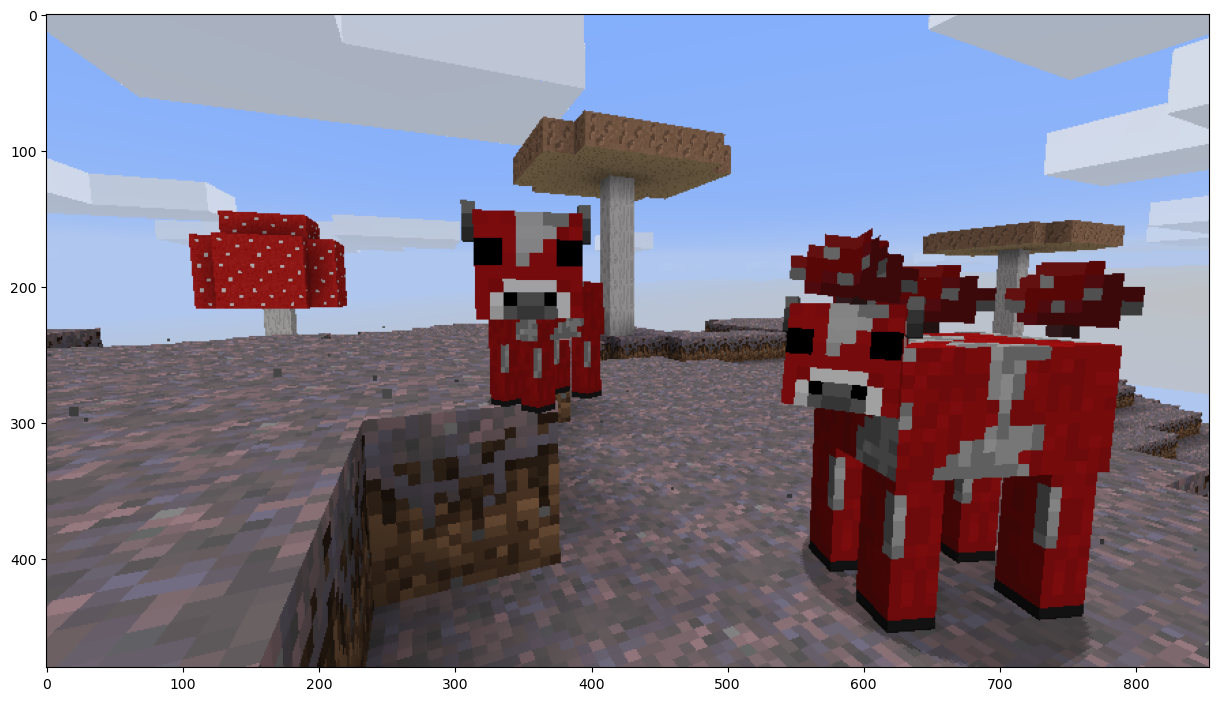

In [12]:
plt.figure(figsize=(15.,10.))
plt.imshow(im)

Переводим в трехмерный numpy массив (x, y, цвет).

In [14]:
import numpy as np

a = np.asarray(im)
a[500:505, 495:500]

array([], shape=(0, 5, 4), dtype=uint8)

Найдем фрагменты изображения, с нужным нам наличием/отсутствием цвета.

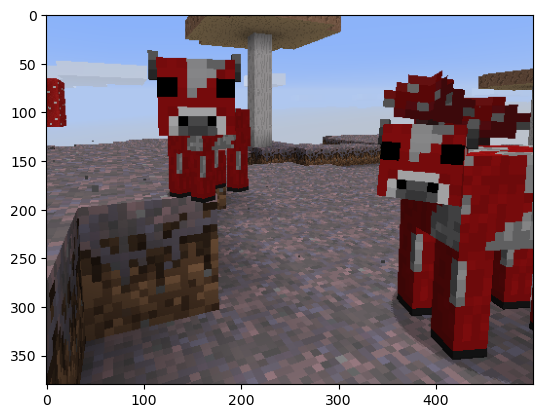

In [38]:
plt.imshow(a[100:854, 200:700])

**Красное:**

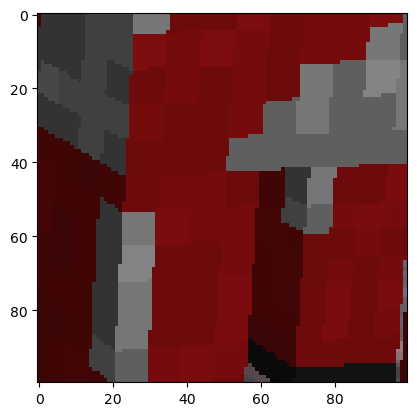

In [47]:
plt.imshow(a[300:400, 600:700])

**Не красное:**

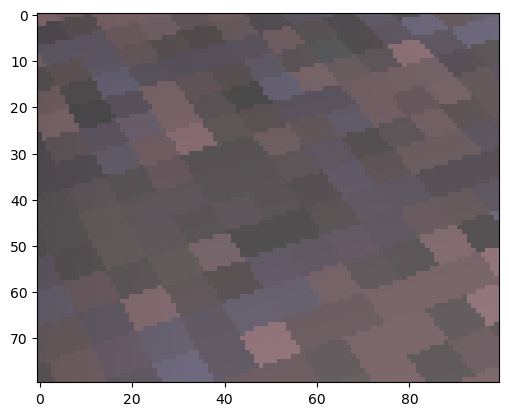

In [39]:
plt.imshow(a[400:500, 380:480])

Подготовка набора данных для обучения.

Желательно, чередовать положительные и отрицательные примеры, при добавлении их в общий массив:

~~y = [0,0,0,1,1,1]~~

`y  = [0,1,0,1,0,1]`.

Должно получиться следующее (*для нейронки с 3-мя входами и одним выходом*):

|x_R|x_G|x_B|y_Target|
|---|---|---|---|
|255|255|0|1|
|0|0|255|0|



Делим данные на обучающую и тестовую выборки вручную **(без использования библиотеки sklearn)**.

Самый простой вариант: каждый **n**-й набор уходит в тестовую выборку.

Проверить, что и в обучающей и в тестовой выборке есть как положительные, так и отрицательные примеры.

Обучение, оценка результатов, вывод весовых коэффициентов

*Это происходит в лабе по другому предмету; когда будет готово, можно будет импортировать код библиотекой, подрубить класс нейронки и проверить, как она работает* :)

Проверка работы `Image.fromarray()` для вывода результатов обучения

In [ ]:
var_1 = np.array([[300,0,300,300,300],
                [100,0,100,100,100],
                [0,0,0,0,0],
                [100,0,100,100,100],
                [0,0,0,0,0]], dtype='uint8')
var_2 = np.array([[[300,300,300],[0,0,0],[300,0,0],[0,300,0],[0,0,300]],
                [[100,0,0],[0,0,0],[100,0,0],[100,0,0],[100,0,0]],
                [[0,0,0],[0,0,0],[0,0,0],[0,0,0],[0,0,0]],
                [[100,0,0],[0,0,0],[100,0,0],[100,0,0],[100,0,0]],
                [[0,0,0],[0,0,0],[0,0,0],[0,0,0],[0,0,0]]], dtype='uint8')
print(var_1.shape)
plt.imshow(Image.fromarray(var_1, mode="L"))
# plt.imshow(Image.fromarray(var_2, mode="RGB"))

# Работает с моделью машинного обучения:

> Тут была магия, которую вам надо реализовать.

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression().fit(x_train, y_train)
model.score(x_test, y_test)


Подготовка данных (всего изображения) для передачи в нейронку.

Обработка данных нейронной сетью.

In [ ]:
res = []
for i in range(len(mas)):
    res.append(100*model.predict(mas[i]))

Преобразование полученного от нейронки списка в массив для вывода на экран.

In [ ]:
our_array = np.array(res, dtype='uint8').reshape(1080,1920)

Проверка количества пикселей, распознанных как красные.

In [ ]:
res.count([100]), res.count([0])

На мой взгляд, топ:

In [ ]:
plt.figure(figsize=(15.,10.))
plt.imshow(Image.fromarray(our_array, mode="L"))